# Email Campaign A/B/C Test Analysis (Hillstrom)

## 1. Problem Statement

### Context
An online clothing retailer ran an email marketing experiment. 64,000 customers who had
purchased within the last 12 months were randomly split into three groups of about 21,300 each:
- **Mens E-Mail** — received an email featuring men's merchandise;
- **Womens E-Mail** — received an email featuring women's merchandise;
- **No E-Mail** — received no email (control group).

For two weeks after the campaign, the retailer tracked whether each customer visited the website,
made a purchase, and how much they spent.

### Business Question
Should the company send the email campaign, and if so, which version: men's or women's?

### Metrics
| Metric | Formula | Role |
|---|---|---|
| Purchase conversion rate | customers who purchased / all customers in the group | **primary** |
| Visit rate | customers who visited the website / all customers in the group | secondary |
| Revenue per customer | total spend in the group / all customers in the group | secondary |

**Why conversion is the primary metric:** the business earns money from purchases, not visits.
Revenue matters, but most customers spend 0 USD, so the variance is high and a test on revenue
is less sensitive. The decision is based on conversion; revenue is analyzed as a supporting metric.

### Hypotheses
p_M, p_W, p_C — purchase conversion rate in the whole customer population with the men's email,
the women's email, and no email.

| Comparison | H₀ | H₁ |
|---|---|---|
| Men's vs Control | p_M = p_C | p_M ≠ p_C |
| Women's vs Control | p_W = p_C | p_W ≠ p_C |
| Men's vs Women's | p_M = p_W | p_M ≠ p_W |

### Significance Level
- α = 0.05, number of comparisons m = 3.
- Bonferroni correction: threshold for each comparison α / m = 0.05 / 3 ≈ **0.0167**.
  Without the correction, the chance of at least one false positive would be 1 − 0.95³ ≈ 14%.
- **Two-sided** tests: an email can either increase or decrease conversion,
  and when comparing the two emails we do not know in advance which one is better.

### Analysis Plan
2. Data quality check
3. Descriptive statistics
4. Randomization check (SRM, group balance)
5. Test power (MDE)
6. Proportion tests: conversion and visits
7. Revenue tests: t-test, bootstrap, Mann–Whitney
8. Segment analysis: which customers respond to which email
9. Business conclusion and recommendation
10. Comparison with other analyses

## 2. Data Quality Check

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

In [2]:
df = pd.read_csv('../data/hillstrom.csv')

In [3]:
df.shape

(64000, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


In [5]:
df.isna().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

In [6]:
df['recency'].between(1, 12).all() # should be 1-12 (months in year)

np.True_

In [7]:
df[(df['history'] < 0) | (df['spend'] < 0)]['recency'].count()

np.int64(0)

In [8]:
for col in ['mens', 'womens', 'newbie', 'visit', 'conversion']:
    print(col, df[col].isin([0, 1]).all())

mens True
womens True
newbie True
visit True
conversion True


In [9]:
for col in ['segment', 'zip_code', 'channel', 'history_segment']:
    print(col, list(df[col].unique()))

segment ['Womens E-Mail', 'No E-Mail', 'Mens E-Mail']
zip_code ['Surburban', 'Rural', 'Urban']
channel ['Phone', 'Web', 'Multichannel']
history_segment ['2) $100 - $200', '3) $200 - $350', '5) $500 - $750', '1) $0 - $100', '6) $750 - $1,000', '4) $350 - $500', '7) $1,000 +']


In [10]:
len(df[(df['spend'] > 0) & (df['conversion'] == 0)])

0

In [11]:
len(df[(df['spend'] == 0) & (df['conversion'] == 1)])

0

In [12]:
len(df[(df['visit'] == 0) & (df['conversion'] == 1)])

0

In [13]:
df.duplicated().sum()

np.int64(6562)

### Conclusion
- The dataset has **64,000 rows and 12 columns**; data types are correct and there are **no missing values**.
- All values are within valid ranges: `recency` is 1–12, `history` and `spend` are non-negative,
  binary columns contain only 0 and 1.
- Categorical columns have no unexpected values. Note: `zip_code` contains the typo `Surburban`
  (instead of *Suburban*) in the original data; it is kept as is.
- The data is logically consistent: `spend > 0` exactly when `conversion = 1`,
  and there are no purchases without a website visit.
- **6,562 rows are exact duplicates.** Since there is no customer ID and each row represents
  a separate customer, these are different customers with identical attributes, so they are kept.

**The data is clean and ready for analysis.**

## 3. Descriptive Statistics

In [14]:
grouped_segment = df.groupby('segment').agg(
    customers=('segment', 'count'),
    visit_rate=('visit', 'mean'),
    conversion_rate=('conversion', 'mean'),
    revenue_per_customer=('spend', 'mean')
)
grouped_segment.round(4)

,customers,visit_rate,conversion_rate,revenue_per_customer
segment,,,,
Mens E-Mail,21307,0.1828,0.0125,1.4226
No E-Mail,21306,0.1062,0.0057,0.6528
Womens E-Mail,21387,0.1514,0.0088,1.0772


In [15]:
print(f'{((df['spend'] == 0).mean() * 100).round(2)} percent of users spent $0')

99.1 percent of users spent $0


In [16]:
(df['spend']).mode()[0]

np.float64(0.0)

In [17]:
grouped_segment_spend = df.groupby('segment').agg(
    customers=('segment', 'count'),
    avg=('spend', 'mean'),
    q25=('spend', lambda x: x.quantile(0.25)),
    q50=('spend', lambda x: x.quantile(0.50)),
    q75=('spend', lambda x: x.quantile(0.75)),
    q90=('spend', lambda x: x.quantile(0.90)),
    q99=('spend', lambda x: x.quantile(0.99)),
)
grouped_segment_spend.round(4)

,customers,avg,q25,q50,q75,q90,q99
segment,,,,,,,
Mens E-Mail,21307,1.4226,0.0,0.0,0.0,0.0,29.99
No E-Mail,21306,0.6528,0.0,0.0,0.0,0.0,0.00
Womens E-Mail,21387,1.0772,0.0,0.0,0.0,0.0,0.00


In [18]:
buyers = df[df['spend'] > 0]

In [19]:
grouped_segment_buyers = buyers.groupby('segment').agg(
    buyers=('segment', 'count'),
    avg=('spend', 'mean'),
    q25=('spend', lambda x: x.quantile(0.25)),
    q50=('spend', lambda x: x.quantile(0.50)),
    q75=('spend', lambda x: x.quantile(0.75)),
    q90=('spend', lambda x: x.quantile(0.90)),
    q99=('spend', lambda x: x.quantile(0.99)),
)
grouped_segment_buyers.round(2)

,buyers,avg,q25,q50,q75,q90,q99
segment,,,,,,,
Mens E-Mail,267,113.53,29.99,66.98,152.72,262.79,499.00
No E-Mail,122,114.00,35.04,88.36,146.17,226.88,487.64
Womens E-Mail,189,121.89,35.20,94.71,163.79,268.04,499.00


In [20]:
buyers[buyers['segment'] == 'Mens E-Mail'].groupby('spend').agg(
    buyers=('spend', 'count')
)

,buyers
spend,
29.99,70
30.24,1
30.94,1
30.98,1
32.17,1
...,...
397.32,1
421.17,1
421.76,1


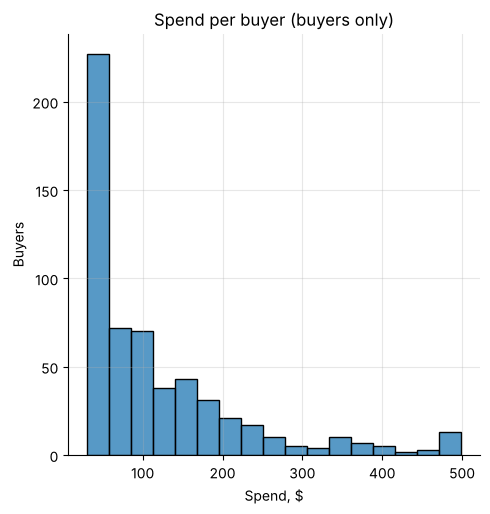

In [21]:
sns.displot(data=buyers, x='spend')
plt.title('Spend per buyer (buyers only)')
plt.xlabel('Spend, $')
plt.ylabel('Buyers')
plt.grid(axis='both', alpha=0.3)
plt.show()

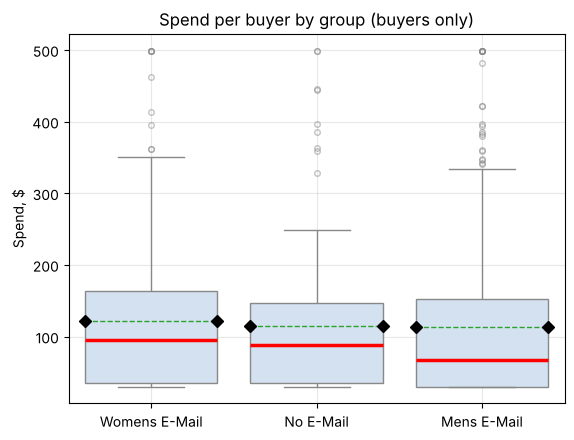

In [22]:
sns.boxplot(data=buyers, x='segment', y='spend', 
            color='#cfe0f5',
            medianprops=dict(color='red', linewidth=2.5),
            flierprops=dict(marker='o', markersize=4, alpha=0.5),
            showmeans=True,
            meanline=True, 
            meanprops=dict(marker='D', markerfacecolor='black', markeredgecolor='black', markersize=6)
           )
plt.title('Spend per buyer by group (buyers only)')
plt.xlabel('')
plt.ylabel('Spend, $')
plt.grid(axis='both', alpha=0.3)
plt.show()

### Conclusion

**Metrics by group** (descriptive only, significance is tested in step 6):

| Group | Visit rate | Conversion rate | Revenue per customer |
|---|---|---|---|
| Mens E-Mail | 18.3% | 1.25% | 1.42 USD |
| Womens E-Mail | 15.1% | 0.88% | 1.08 USD |
| No E-Mail | 10.6% | 0.57% | 0.65 USD |

Both emails show higher values than the control group; the men's email is the highest on all three metrics.

- **99.1% of customers made no purchase** during the test: the mode of `spend` is 0
  and all percentiles up to the 90th are 0.
- **578 customers made a purchase.** Their average order is 114–122 USD and the median is 67–95 USD,
  with a long right tail up to 499 USD.
- The men's email has the most buyers (267) but the **lowest median order (67 USD)**:
  26% of its purchases are exactly 29.99 USD, compared to about 21% in the other groups.
- **Data features:** many purchases are exactly 29.99 USD, and 12 buyers spent exactly 499 USD,
  the maximum value, so `spend` may be capped at 499 USD in the source data.

## 4. Randomization Check

In [23]:
grouped_segment_history = df.groupby('segment').agg(
    avg=('history', 'mean'),
    q25=('history', lambda x: x.quantile(0.25)),
    q50=('history', lambda x: x.quantile(0.50)),
    q75=('history', lambda x: x.quantile(0.75)),
    q90=('history', lambda x: x.quantile(0.90)),
    q99=('history', lambda x: x.quantile(0.99)),
)
grouped_segment_history.round(2)

,avg,q25,q50,q75,q90,q99
segment,,,,,,
Mens E-Mail,242.84,63.58,157.22,325.22,563.63,1229.96
No E-Mail,240.88,65.30,156.66,325.17,561.06,1191.89
Womens E-Mail,242.54,65.04,160.09,326.82,558.16,1239.73


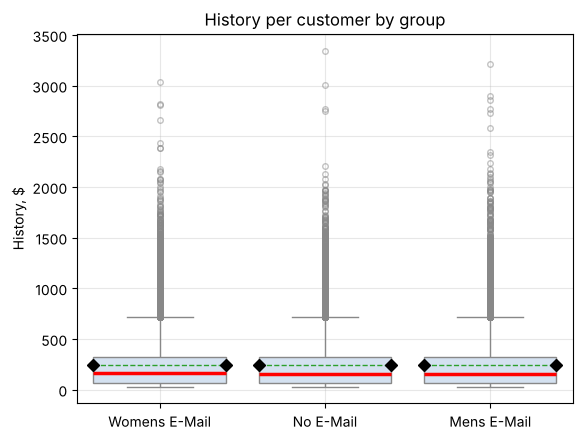

In [24]:
sns.boxplot(data=df, x='segment', y='history', 
            color='#cfe0f5',
            medianprops=dict(color='red', linewidth=2.5),
            flierprops=dict(marker='o', markersize=4, alpha=0.5),
            showmeans=True,
            meanline=True, 
            meanprops=dict(marker='D', markerfacecolor='black', markeredgecolor='black', markersize=6)
            )
plt.title('History per customer by group')
plt.xlabel('')
plt.ylabel('History, $')
plt.grid(axis='both', alpha=0.3)
plt.show()

In [25]:
crosstab_channel = pd.crosstab(df['segment'], df['channel'], normalize='index')

crosstab_channel.round(4)

channel,Multichannel,Phone,Web
segment,,,
Mens E-Mail,0.1209,0.4337,0.4454
No E-Mail,0.1223,0.4378,0.4399
Womens E-Mail,0.1206,0.4420,0.4374


In [26]:
crosstab_zip_code = pd.crosstab(df['segment'], df['zip_code'], normalize='index')

crosstab_zip_code.round(4)

zip_code,Rural,Surburban,Urban
segment,,,
Mens E-Mail,0.1522,0.4459,0.4019
No E-Mail,0.1473,0.4518,0.4009
Womens E-Mail,0.1487,0.4512,0.4001


In [27]:
crosstab_history_segment = pd.crosstab(df['segment'], df['history_segment'], normalize='index')

crosstab_history_segment.round(4)

history_segment,1) $0 - $100,2) $100 - $200,3) $200 - $350,4) $350 - $500,5) $500 - $750,"6) $750 - $1,000","7) $1,000 +"
segment,,,,,,,
Mens E-Mail,0.3625,0.2202,0.1920,0.0984,0.0750,0.0302,0.0218
No E-Mail,0.3573,0.2270,0.1898,0.0997,0.0775,0.0292,0.0195
Womens E-Mail,0.3569,0.2210,0.1943,0.1023,0.0777,0.0277,0.0200


In [28]:
crosstab_newbie = pd.crosstab(df['segment'], df['newbie'], normalize='index')

crosstab_newbie.round(4)

newbie,0,1
segment,,
Mens E-Mail,0.4985,0.5015
No E-Mail,0.4980,0.5020
Womens E-Mail,0.4968,0.5032


In [29]:
n = len(df)
p0 = 1/3
SE = np.sqrt(p0 * (1 - p0) / n)
print(f'Share should be between {(1/3 - SE).round(4)} and {(1/3 + SE).round(4)}')
rows = []
for key, value in df['segment'].value_counts().items():
    p_hat = value / n
    z = (p_hat - p0) / SE
    rows.append({
        'segment': key,
        'n': value,
        'share': p_hat,
        'z': z,
        'p_value': 2 * norm.sf(abs(z)),
        'p_value_binom': stats.binomtest(value, n, p0).pvalue
    })
print(pd.DataFrame(rows).round(4))

print(f'p-value of all segments are greater 0.001 so no SRM')

Share should be between 0.3315 and 0.3352
         segment      n   share       z  p_value  p_value_binom
0  Womens E-Mail  21387  0.3342  0.4500   0.6527         0.6537
1    Mens E-Mail  21307  0.3329 -0.2208   0.8252         0.8274
2      No E-Mail  21306  0.3329 -0.2292   0.8187         0.8209
p-value of all segments are greater 0.001 so no SRM


In [30]:
df.groupby('segment')[['recency', 'history', 'newbie', 'mens', 'womens']].mean().round(4)

,recency,history,newbie,mens,womens
segment,,,,,
Mens E-Mail,5.7736,242.8359,0.5015,0.5509,0.5514
No E-Mail,5.7497,240.8827,0.5020,0.5532,0.5476
Womens E-Mail,5.7678,242.5366,0.5032,0.5489,0.5501


### Conclusion

**No sample ratio mismatch (SRM).** Each group's share was tested against the expected 1/3:

| Group | Customers | Share | p-value (z-test) | p-value (binomial) |
|---|---|---|---|---|
| Womens E-Mail | 21,387 | 33.42% | 0.653 | 0.654 |
| Mens E-Mail | 21,307 | 33.29% | 0.825 | 0.827 |
| No E-Mail | 21,306 | 33.29% | 0.819 | 0.821 |

All p-values are far above the 0.001 threshold. The z-test (normal approximation)
and the exact binomial test give nearly identical results.

**Groups are balanced on pre-test customer attributes:**
- `recency`: mean 5.75–5.77 months in all groups;
- `history`: mean 240.9–242.8 USD, median 156.7–160.1 USD (differences below 1%);
- `newbie`, `mens`, `womens`, `channel`, `zip_code`, `history_segment`:
  shares differ by less than 1 percentage point between groups.

**Randomization worked:** the groups differ only in the email they received,
so differences in test metrics can be attributed to the email.

## 5. Test Power (MDE)

In [31]:
control = df[df['segment'] == 'No E-Mail']
n = len(control)
alpha = 0.05 / 3
power = 0.8
z_alpha = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(power)
for metric in ['conversion', 'visit']:
    p = control[metric].mean()
    SE = np.sqrt(2 * p * (1 - p) / n)
    MDE = (z_alpha + z_power) * SE
    print(f'{metric}: base {p * 100:.2f}%, MDE {MDE * 100:.3f} p.p. '
          f'({MDE / p * 100:.1f}% relative)')

conversion: base 0.57%, MDE 0.237 p.p. (41.3% relative)
visit: base 10.62%, MDE 0.966 p.p. (9.1% relative)


### Conclusion

MDE was calculated for each email vs control (two-sided test, α = 0.05 / 3 ≈ 0.0167,
80% power, about 21,300 customers per group, control group as the baseline):

| Metric | Control rate | MDE (absolute) | MDE (relative) |
|---|---|---|---|
| Conversion | 0.57% | 0.237 p.p. (~50 buyers per group) | 41.3% |
| Visit rate | 10.62% | 0.966 p.p. | 9.1% |

- The test can reliably detect only **large** changes in conversion: about +41% relative to the
  control rate (or the same decrease). Smaller effects may be missed, so a non-significant result
  would mean "the test is too small to see the effect", not "the email does not work".
- The test is much more sensitive for visits (MDE 9.1%), because the visit rate is much higher
  than the conversion rate.
- For the men's vs women's comparison the MDE is slightly larger, because the baseline conversion
  of the email groups is higher than in the control group.

## 6. Proportion Tests: Conversion and Visits

### Pairwise comparisons

Each email is compared with the control group, and the two emails are compared with each other.
The difference is always **group B − group A**, so a positive value means group B is higher.

- **z-test:** SE uses the pooled share p̂ (the H₀ world, where both shares are equal).
- **Confidence interval:** SE uses the two group shares separately.
- The interval uses z = 2.394 (not 1.96), so it matches the Bonferroni threshold 0.0167:
  if the interval does not contain 0, the difference is significant.

In [32]:
alpha = 0.05 / 3
z_crit = norm.ppf(1 - alpha / 2)    # 2.394

pairs = [('No E-Mail', 'Mens E-Mail'),
         ('No E-Mail', 'Womens E-Mail'),
         ('Womens E-Mail', 'Mens E-Mail')]
metrics = ['conversion', 'visit']

rows = []
for group_a, group_b in pairs:
    a = df[df['segment'] == group_a]
    b = df[df['segment'] == group_b]
    for metric in metrics:
        x_a, n_a = a[metric].sum(), len(a)
        x_b, n_b = b[metric].sum(), len(b)
        p_a, p_b = x_a / n_a, x_b / n_b
        diff = p_b - p_a

        # z-test: pooled SE (H0 world)
        p_pool = (x_a + x_b) / (n_a + n_b)
        se_test = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
        z = diff / se_test
        p_value = 2 * norm.sf(abs(z))

        # confidence interval: unpooled SE
        se_ci = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)

        rows.append({
            'metric': metric,
            'group_a': group_a,
            'group_b': group_b,
            'rate_a_%': p_a * 100,
            'rate_b_%': p_b * 100,
            'diff_pp': diff * 100,
            'relative_%': diff / p_a * 100,
            'ci_low_pp': (diff - z_crit * se_ci) * 100,
            'ci_high_pp': (diff + z_crit * se_ci) * 100,
            'z': z,
            'p_value': p_value,
            'significant': p_value <= alpha,
        })

prop_results = pd.DataFrame(rows)

# p-values are kept as numbers in prop_results; formatting is only for display
display_props = prop_results.round(3)
display_props['p_value'] = prop_results['p_value'].apply(lambda p: '< 0.001' if p < 0.001 else f'{p:.3f}')
display_props

,metric,group_a,group_b,rate_a_%,rate_b_%,diff_pp,relative_%,ci_low_pp,ci_high_pp,z,p_value,significant
0,conversion,No E-Mail,Mens E-Mail,0.573,1.253,0.681,118.842,0.460,0.901,7.385,< 0.001,True
1,visit,No E-Mail,Mens E-Mail,10.617,18.276,7.659,72.140,6.848,8.470,22.486,< 0.001,True
2,conversion,No E-Mail,Womens E-Mail,0.573,0.884,0.311,54.331,0.114,0.508,3.780,< 0.001,True
3,visit,No E-Mail,Womens E-Mail,10.617,15.140,4.523,42.606,3.749,5.298,13.949,< 0.001,True
4,conversion,Womens E-Mail,Mens E-Mail,0.884,1.253,0.369,41.800,0.131,0.608,3.713,< 0.001,True
5,visit,Womens E-Mail,Mens E-Mail,15.140,18.276,3.136,20.711,2.272,3.999,8.685,< 0.001,True


**Check with statsmodels.** The manual z-test and interval should match `proportions_ztest`
and `confint_proportions_2indep(method='wald')`.

In [33]:
checks = []
for _, row in prop_results.iterrows():
    a = df[df['segment'] == row['group_a']][row['metric']]
    b = df[df['segment'] == row['group_b']][row['metric']]
    z_sm, p_sm = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
    ci_low, ci_high = confint_proportions_2indep(b.sum(), len(b), a.sum(), len(a),
                                                 method='wald', alpha=alpha)
    checks.append({
        'metric': row['metric'],
        'group_a': row['group_a'],
        'group_b': row['group_b'],
        'z_diff': abs(z_sm - row['z']),
        'ci_low_diff': abs(ci_low * 100 - row['ci_low_pp']),
        'ci_high_diff': abs(ci_high * 100 - row['ci_high_pp']),
    })

pd.DataFrame(checks)    # all differences should be ~0

,metric,group_a,group_b,z_diff,ci_low_diff,ci_high_diff
0,conversion,No E-Mail,Mens E-Mail,0.0,1.665335e-16,1.110223e-16
1,visit,No E-Mail,Mens E-Mail,0.0,0.000000e+00,0.000000e+00
2,conversion,No E-Mail,Womens E-Mail,0.0,8.326673e-17,1.110223e-16
3,visit,No E-Mail,Womens E-Mail,0.0,8.881784e-16,0.000000e+00
4,conversion,Womens E-Mail,Mens E-Mail,0.0,8.326673e-17,1.110223e-16
5,visit,Womens E-Mail,Mens E-Mail,0.0,4.440892e-16,0.000000e+00


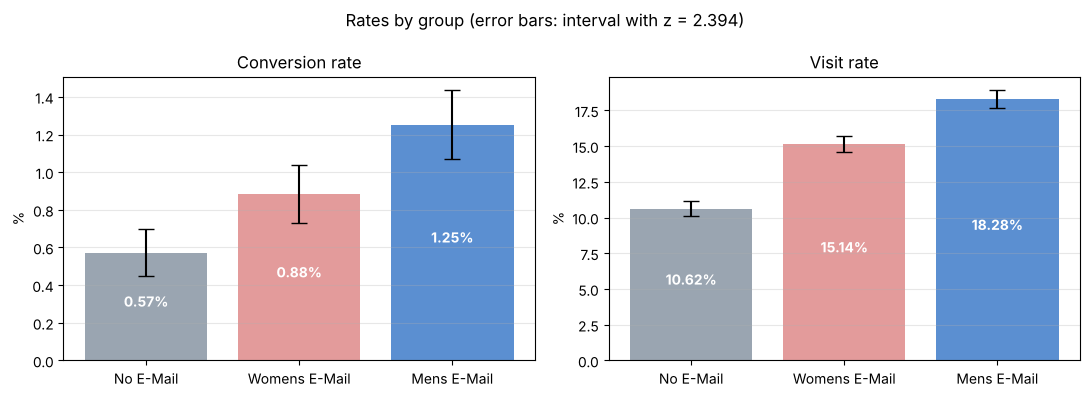

In [34]:
order = ['No E-Mail', 'Womens E-Mail', 'Mens E-Mail']
colors = ['#9aa5b1', '#e39b9b', '#5b8fd1']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ['conversion', 'visit'], ['Conversion rate', 'Visit rate']):
    rates, errors = [], []
    for group in order:
        x = df[df['segment'] == group][metric]
        p = x.mean()
        rates.append(p * 100)
        errors.append(z_crit * np.sqrt(p * (1 - p) / len(x)) * 100)   # interval for each group's rate
    ax.bar(order, rates, yerr=errors, capsize=6, color=colors)
    for i, r in enumerate(rates):
        ax.text(i, r / 2, f'{r:.2f}%', ha='center', color='white', fontweight='bold')
    ax.set_title(title)
    ax.set_ylabel('%')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Rates by group (error bars: interval with z = 2.394)')
plt.tight_layout()
plt.savefig('../images/rates_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

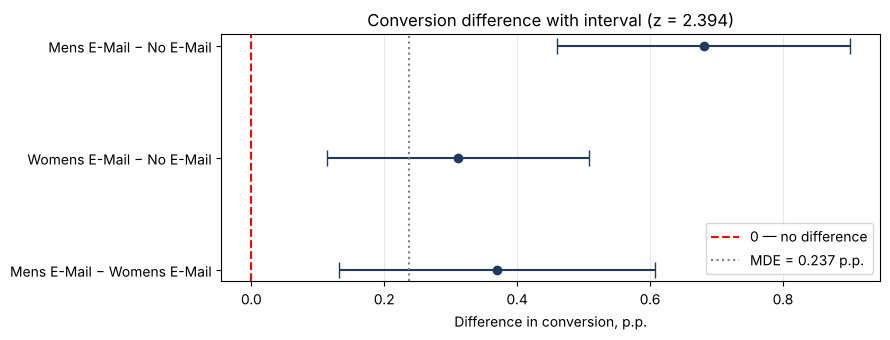

In [35]:
# conversion differences with confidence intervals, compared with the MDE from step 5
conv = prop_results[prop_results['metric'] == 'conversion'].reset_index(drop=True)
labels = [f"{b} − {a}" for a, b in zip(conv['group_a'], conv['group_b'])]
mde_pp = 0.237    # MDE from step 5 (email vs control)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(conv['diff_pp'], range(len(conv)),
            xerr=[conv['diff_pp'] - conv['ci_low_pp'], conv['ci_high_pp'] - conv['diff_pp']],
            fmt='o', color='#1f3a5f', capsize=6)
ax.axvline(0, color='red', linestyle='--', label='0 — no difference')
ax.axvline(mde_pp, color='grey', linestyle=':', label=f'MDE = {mde_pp} p.p.')
ax.set_yticks(range(len(conv)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel('Difference in conversion, p.p.')
ax.set_title('Conversion difference with interval (z = 2.394)')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../images/conversion_differences.png', dpi=150, bbox_inches='tight')
plt.show()

### Conclusion

**All six comparisons are significant** at the Bonferroni threshold 0.0167 (all p-values < 0.001).

| Comparison | Conversion | Difference, p.p. (relative) | Interval, p.p. | Visits | Difference, p.p. (relative) | Interval, p.p. |
|---|---|---|---|---|---|---|
| Mens − No E-Mail | 1.253% vs 0.573% | **+0.68** (+119%) | 0.46 to 0.90 | 18.28% vs 10.62% | **+7.66** (+72%) | 6.85 to 8.47 |
| Womens − No E-Mail | 0.884% vs 0.573% | **+0.31** (+54%) | 0.11 to 0.51 | 15.14% vs 10.62% | **+4.52** (+43%) | 3.75 to 5.30 |
| Mens − Womens | 1.253% vs 0.884% | **+0.37** (+42%) | 0.13 to 0.61 | 18.28% vs 15.14% | **+3.14** (+21%) | 2.27 to 4.00 |

- **Both emails work.** Each email increases both visits and conversion compared with no email.
- **The men's email is stronger than the women's email** on both metrics: +0.37 p.p. conversion and +3.14 p.p. visits.
- All observed conversion differences are larger than the MDE from step 5 (0.237 p.p.), so the test had enough power to detect them.
- None of the intervals contains 0, which agrees with the p-values.
- The manual calculations match `statsmodels` (differences ≈ 0).

Note: on the bar chart, the error bars of the two email groups overlap, but the difference between them is still significant.
Overlapping intervals of two separate groups do not mean "no difference" — the difference itself has to be tested, as in the table above.

## 7. Revenue Tests

Revenue per customer (`spend`) is very skewed: 99.1% of customers spent 0 and a few spent up to 499 USD.
The difference in means is checked with three methods:

| Method | What it compares | Why |
|---|---|---|
| Welch t-test | means | standard test for revenue; with n ≈ 21,000 the mean is approximately normal |
| Bootstrap | means | interval without assumptions about the shape of the data |
| Mann–Whitney | whole distributions | robust to outliers, but answers a different question (not about means) |

SE for the t-test and the interval: √(s_A²/n_A + s_B²/n_B). The interval uses z = 2.394, as in step 6.

In [36]:
rng = np.random.default_rng(42)    # fixed seed: bootstrap results are reproducible
n_boot = 10_000

rows = []
boot_diffs = {}
for group_a, group_b in pairs:
    a = df[df['segment'] == group_a]['spend'].values
    b = df[df['segment'] == group_b]['spend'].values
    diff = b.mean() - a.mean()

    # Welch t-test by hand
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    t = diff / se
    p_value = 2 * norm.sf(abs(t))                       # n is large: t-distribution ≈ z
    p_scipy = stats.ttest_ind(b, a, equal_var=False).pvalue

    # bootstrap interval for the difference in means
    diffs = np.array([rng.choice(b, size=len(b)).mean() - rng.choice(a, size=len(a)).mean()
                      for _ in range(n_boot)])
    boot_low, boot_high = np.percentile(diffs, [alpha / 2 * 100, (1 - alpha / 2) * 100])
    boot_diffs[(group_a, group_b)] = diffs

    # Mann-Whitney
    p_mw = stats.mannwhitneyu(b, a, alternative='two-sided').pvalue

    rows.append({
        'group_a': group_a,
        'group_b': group_b,
        'mean_a': a.mean(),
        'mean_b': b.mean(),
        'diff': diff,
        'relative_%': diff / a.mean() * 100,
        't': t,
        'p_welch': p_value,
        'p_welch_scipy': p_scipy,
        'ci_low': diff - z_crit * se,
        'ci_high': diff + z_crit * se,
        'boot_low': boot_low,
        'boot_high': boot_high,
        'p_mann_whitney': p_mw,
        'significant_welch': p_value <= alpha,
    })

revenue_results = pd.DataFrame(rows)
revenue_results.round(4)

,group_a,group_b,mean_a,mean_b,diff,relative_%,t,p_welch,p_welch_scipy,ci_low,ci_high,boot_low,boot_high,p_mann_whitney,significant_welch
0,No E-Mail,Mens E-Mail,0.6528,1.4226,0.7698,117.9289,5.3001,0.0000,0.0000,0.4221,1.1175,0.4177,1.1210,0.0000,True
1,No E-Mail,Womens E-Mail,0.6528,1.0772,0.4244,65.0152,3.2564,0.0011,0.0011,0.1124,0.7364,0.1181,0.7384,0.0002,True
2,Womens E-Mail,Mens E-Mail,1.0772,1.4226,0.3454,32.0660,2.1640,0.0305,0.0305,-0.0367,0.7275,-0.0397,0.7229,0.0002,False


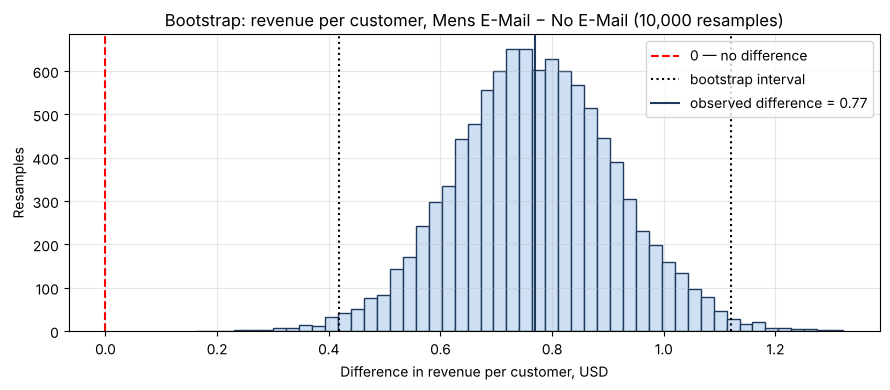

In [37]:
diffs = boot_diffs[('No E-Mail', 'Mens E-Mail')]
row = revenue_results.iloc[0]

plt.figure(figsize=(9, 4))
plt.hist(diffs, bins=50, color='#cfe0f5', edgecolor='#1f3a5f')
plt.axvline(0, color='red', linestyle='--', label='0 — no difference')
plt.axvline(row['boot_low'], color='black', linestyle=':', label='bootstrap interval')
plt.axvline(row['boot_high'], color='black', linestyle=':')
plt.axvline(row['diff'], color='#1f3a5f', label=f"observed difference = {row['diff']:.2f}")
plt.title('Bootstrap: revenue per customer, Mens E-Mail − No E-Mail (10,000 resamples)')
plt.xlabel('Difference in revenue per customer, USD')
plt.ylabel('Resamples')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../images/bootstrap_mens_vs_control.png', dpi=150, bbox_inches='tight')
plt.show()

**Where does the revenue lift come from?** Revenue per customer = conversion × average order value (AOV).
If AOV among buyers does not change, the whole lift comes from more buyers.

In [38]:
rows = []
for group_a, group_b in pairs:
    a = buyers[buyers['segment'] == group_a]['spend']
    b = buyers[buyers['segment'] == group_b]['spend']
    rows.append({
        'group_a': group_a,
        'group_b': group_b,
        'buyers_a': len(a),
        'buyers_b': len(b),
        'aov_a': a.mean(),
        'aov_b': b.mean(),
        'aov_diff': b.mean() - a.mean(),
        'p_welch': stats.ttest_ind(b, a, equal_var=False).pvalue,
        'p_mann_whitney': stats.mannwhitneyu(b, a, alternative='two-sided').pvalue,
    })

aov_results = pd.DataFrame(rows)
aov_results.round(3)

,group_a,group_b,buyers_a,buyers_b,aov_a,aov_b,aov_diff,p_welch,p_mann_whitney
0,No E-Mail,Mens E-Mail,122,267,114.003,113.527,-0.476,0.967,0.321
1,No E-Mail,Womens E-Mail,122,189,114.003,121.895,7.892,0.515,0.509
2,Womens E-Mail,Mens E-Mail,189,267,121.895,113.527,-8.368,0.417,0.097


### Conclusion

| Comparison | Revenue per customer | Difference (relative) | Welch p-value | Interval (Welch) | Interval (bootstrap) | Mann–Whitney p-value |
|---|---|---|---|---|---|---|
| Mens − No E-Mail | 1.42 vs 0.65 USD | **+0.77 USD** (+118%) | < 0.001 | 0.42 to 1.12 | 0.42 to 1.12 | < 0.001 |
| Womens − No E-Mail | 1.08 vs 0.65 USD | **+0.42 USD** (+65%) | 0.001 | 0.11 to 0.74 | 0.12 to 0.74 | < 0.001 |
| Mens − Womens | 1.42 vs 1.08 USD | +0.35 USD (+32%) | 0.031 | −0.04 to 0.73 | −0.04 to 0.72 | < 0.001 |

- **Both emails significantly increase revenue per customer** compared with no email.
- **Men's vs women's email: the difference in revenue is not significant** at 0.0167 (p = 0.031, both intervals contain 0).
  The men's email is probably better (it is better on conversion and visits), but the revenue data is too noisy to prove it.
- **Welch and bootstrap agree** (intervals differ only in the second decimal), so with about 21,000 customers per group the t-test works even for this very skewed metric.
- **Mann–Whitney gives a different answer for Mens − Womens** (p < 0.001). With 99% zeros it mostly compares the share of buyers, which is already tested in step 6,
  not the mean revenue. So it is not used for the revenue decision.
- **Average order value (AOV) does not change**: 114 USD in control vs 114 USD (men's email) and 122 USD (women's email), all p-values > 0.4.
  Revenue per customer = conversion × AOV, so **the whole revenue lift comes from more buyers, not from bigger orders.**

## 8. Segment Analysis

**Question:** does each email work for all customers, or only for some of them?

Segments were chosen **before** looking at the results:

| Segment | Values |
|---|---|
| `newbie` | existing / new customer |
| `purchase_history` (from `mens`, `womens`) | bought men's only / women's only / both |
| `channel` | Phone / Web / Multichannel |
| `zip_code` | Urban / Surburban / Rural |
| `history_level` | past-year spend below / at or above the median |

Each email is compared with the control group inside every segment value:
13 values × 2 emails = **26 comparisons**, so the Bonferroni threshold is 0.05 / 26 ≈ **0.0019**.
Metric: conversion (primary).

Segments are much smaller than the whole groups, so the power is lower:
a non-significant result in a segment does not prove that the email does not work there.

In [39]:
df['purchase_history'] = np.select(
    [(df['mens'] == 1) & (df['womens'] == 0), (df['mens'] == 0) & (df['womens'] == 1)],
    ['mens only', 'womens only'],
    default='both',
)
df['history_level'] = np.where(df['history'] >= df['history'].median(), 'high', 'low')
df['newbie_label'] = df['newbie'].map({0: 'existing', 1: 'new'})

segment_columns = {
    'newbie': 'newbie_label',
    'purchase_history': 'purchase_history',
    'channel': 'channel',
    'zip_code': 'zip_code',
    'history_level': 'history_level',
}
emails = ['Mens E-Mail', 'Womens E-Mail']

n_comparisons = sum(df[col].nunique() for col in segment_columns.values()) * len(emails)
alpha_seg = 0.05 / n_comparisons
z_seg = norm.ppf(1 - alpha_seg / 2)
print(f'{n_comparisons} comparisons, threshold = {alpha_seg:.4f}, z = {z_seg:.3f}')

rows = []
for segment, col in segment_columns.items():
    for value in sorted(df[col].unique()):
        part = df[df[col] == value]
        a = part[part['segment'] == 'No E-Mail']['conversion']
        for email in emails:
            b = part[part['segment'] == email]['conversion']
            x_a, n_a, x_b, n_b = a.sum(), len(a), b.sum(), len(b)
            p_a, p_b = x_a / n_a, x_b / n_b
            p_pool = (x_a + x_b) / (n_a + n_b)
            se_test = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
            se_ci = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
            z = (p_b - p_a) / se_test
            p_value = 2 * norm.sf(abs(z))
            rows.append({
                'segment': segment,
                'value': value,
                'email': email,
                'n_control': n_a,
                'n_email': n_b,
                'conv_control_%': p_a * 100,
                'conv_email_%': p_b * 100,
                'diff_pp': (p_b - p_a) * 100,
                'ci_low_pp': (p_b - p_a - z_seg * se_ci) * 100,
                'ci_high_pp': (p_b - p_a + z_seg * se_ci) * 100,
                'p_value': p_value,
                'significant': p_value <= alpha_seg,
            })

segment_results = pd.DataFrame(rows)
segment_results.round(4)

26 comparisons, threshold = 0.0019, z = 3.102


,segment,value,email,n_control,n_email,conv_control_%,conv_email_%,diff_pp,ci_low_pp,ci_high_pp,p_value,significant
0,newbie,existing,Mens E-Mail,10611,10621,0.7728,1.3935,0.6207,0.1802,1.0611,0.0000,True
1,newbie,existing,Womens E-Mail,10611,10624,0.7728,0.8660,0.0932,-0.2906,0.4769,0.4514,False
2,newbie,new,Mens E-Mail,10695,10686,0.3740,1.1136,0.7396,0.3754,1.1038,0.0000,True
3,newbie,new,Womens E-Mail,10695,10763,0.3740,0.9012,0.5272,0.1905,0.8639,0.0000,True
4,purchase_history,both,Mens E-Mail,2149,2181,0.9307,2.4301,1.4994,0.2916,2.7072,0.0001,True
5,purchase_history,both,Womens E-Mail,2149,2118,0.9307,1.4636,0.5330,-0.5004,1.5664,0.1092,False
6,purchase_history,mens only,Mens E-Mail,9638,9558,0.5499,1.1509,0.6010,0.1897,1.0122,0.0000,True
7,purchase_history,mens only,Womens E-Mail,9638,9622,0.5499,0.6132,0.0633,-0.2766,0.4032,0.5637,False
8,purchase_history,womens only,Mens E-Mail,9519,9568,0.5148,1.0870,0.5722,0.1723,0.9720,0.0000,True
9,purchase_history,womens only,Womens E-Mail,9519,9647,0.5148,1.0262,0.5115,0.1202,0.9027,0.0001,True


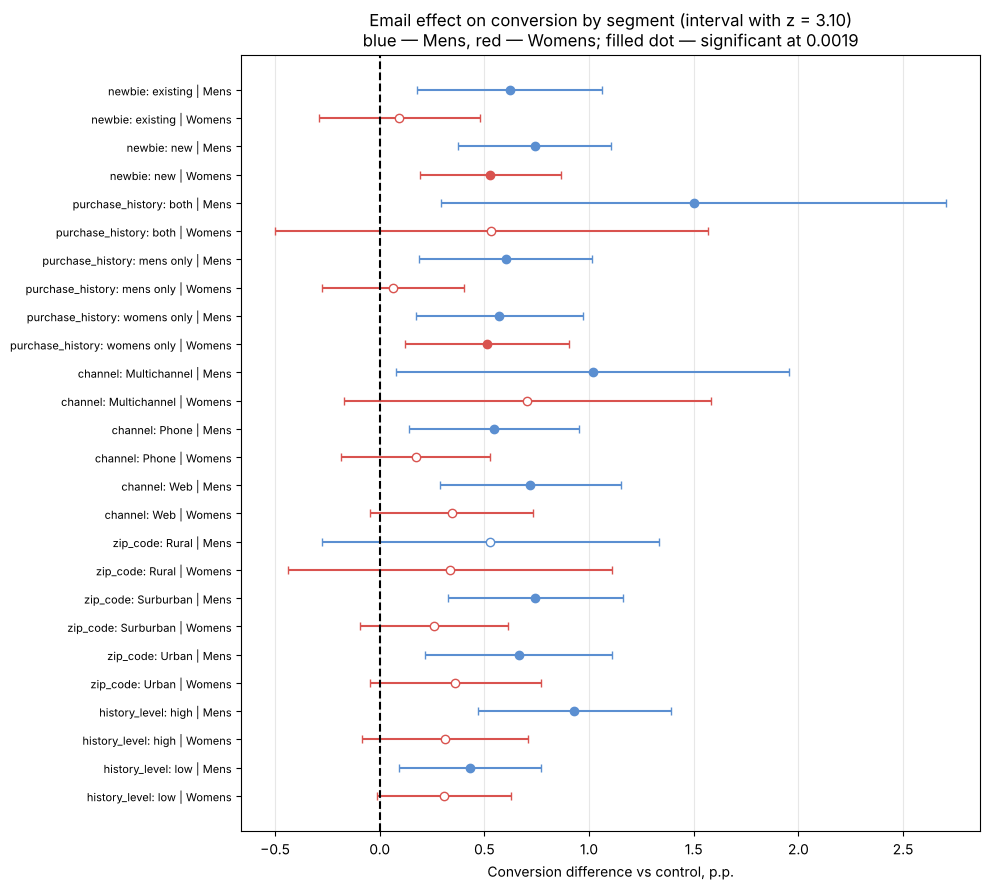

In [40]:
fig, ax = plt.subplots(figsize=(10, 9))
labels = []
for i, (_, row) in enumerate(segment_results.iterrows()):
    color = '#5b8fd1' if row['email'] == 'Mens E-Mail' else '#d9534f'
    face = color if row['significant'] else 'white'    # filled dot = significant
    ax.errorbar(row['diff_pp'], i,
                xerr=[[row['diff_pp'] - row['ci_low_pp']], [row['ci_high_pp'] - row['diff_pp']]],
                fmt='o', color=color, markerfacecolor=face, capsize=3)
    labels.append(f"{row['segment']}: {row['value']} | {row['email'].replace(' E-Mail', '')}")

ax.axvline(0, color='black', linestyle='--')
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Conversion difference vs control, p.p.')
ax.set_title(f'Email effect on conversion by segment (interval with z = {z_seg:.2f})\n'
             'blue — Mens, red — Womens; filled dot — significant at 0.0019')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../images/segments_conversion.png', dpi=150, bbox_inches='tight')
plt.show()

**Descriptive view by purchase history:** conversion and revenue per customer for all three groups.

In [41]:
by_history = df.pivot_table(index='purchase_history', columns='segment',
                            values=['conversion', 'spend'], aggfunc='mean')
by_history['conversion'] = by_history['conversion'] * 100
by_history.round(2)

conversion                               spend            \
segment          Mens E-Mail No E-Mail Womens E-Mail Mens E-Mail No E-Mail   
purchase_history                                                             
both                    2.43      0.93          1.46        3.01      1.18   
mens only               1.15      0.55          0.61        1.38      0.70   
womens only             1.09      0.51          1.03        1.11      0.49   

                                
segment          Womens E-Mail  
purchase_history                
both                      1.34  
mens only                 0.97  
womens only               1.12

### Conclusion

26 comparisons, Bonferroni threshold 0.0019. Segment results are **exploratory**: segments are smaller, so the power is lower,
and a non-significant result does not prove that there is no effect.

**Men's email: works almost everywhere.** It is significant in 12 of 13 segment values; the exception is Rural (+0.53 p.p., p = 0.043, only about 3,200 customers per group).
The largest lifts:
- customers who bought **both** men's and women's products: +1.50 p.p. (0.93% → 2.43%)
- **Multichannel** customers: +1.02 p.p. (0.69% → 1.71%)
- customers with **high past-year spend**: +0.93 p.p. (0.73% → 1.66%)

It also works for customers who bought **only women's products** (+0.57 p.p.).

**Women's email: works only for two segments.**
- **new customers**: +0.53 p.p. (0.37% → 0.90%)
- customers who bought **only women's products**: +0.51 p.p. (0.51% → 1.03%)

For existing customers (+0.09 p.p.) and customers who bought only men's products (+0.06 p.p.) there is no visible effect.

**Women's-only buyers are the one group where the two emails are similar:**
conversion 1.09% (men's email) vs 1.03% (women's email), revenue per customer 1.11 vs 1.12 USD.
Everywhere else the men's email is ahead.

## 9. Business Conclusion

**Incremental effect per 1,000 emails** = (metric with email − metric in control) × 1,000.
Revenue in this dataset is sales, not profit, so the profit estimate needs two assumptions.
They are parameters below and can be changed.

In [42]:
margin = 0.40                 # assumption: gross margin of an online clothing retailer
cost_per_1000_emails = 10     # assumption: sending cost per 1,000 emails, USD

control = df[df['segment'] == 'No E-Mail']
rows = []
for email in ['Mens E-Mail', 'Womens E-Mail']:
    group = df[df['segment'] == email]
    extra_visitors = (group['visit'].mean() - control['visit'].mean()) * 1000
    extra_buyers = (group['conversion'].mean() - control['conversion'].mean()) * 1000
    extra_revenue = (group['spend'].mean() - control['spend'].mean()) * 1000
    rev = revenue_results[(revenue_results['group_a'] == 'No E-Mail') &
                          (revenue_results['group_b'] == email)].iloc[0]
    rows.append({
        'email': email,
        'extra_visitors': extra_visitors,
        'extra_buyers': extra_buyers,
        'extra_revenue_usd': extra_revenue,
        'revenue_ci_low_usd': rev['ci_low'] * 1000,
        'revenue_ci_high_usd': rev['ci_high'] * 1000,
        'extra_profit_usd': extra_revenue * margin - cost_per_1000_emails,
        'profit_worst_case_usd': rev['ci_low'] * 1000 * margin - cost_per_1000_emails,
    })

impact = pd.DataFrame(rows).set_index('email')
print('Per 1,000 emails sent:')
impact.round(1)

Per 1,000 emails sent:


,extra_visitors,extra_buyers,extra_revenue_usd,revenue_ci_low_usd,revenue_ci_high_usd,extra_profit_usd,profit_worst_case_usd
email,,,,,,,
Mens E-Mail,76.6,6.8,769.8,422.1,1117.5,297.9,158.8
Womens E-Mail,45.2,3.1,424.4,112.4,736.4,159.8,35.0


### Conclusion

**Per 1,000 emails sent** (difference vs no email):

| | Men's email | Women's email |
|---|---|---|
| Extra visitors | +77 | +45 |
| Extra buyers | +6.8 | +3.1 |
| Extra revenue | **+770 USD** (422 to 1,118) | **+424 USD** (112 to 736) |
| Extra profit (40% margin − 10 USD sending cost) | +298 USD | +160 USD |
| Profit at the lower bound of the interval | +159 USD | +35 USD |

**Decision.** Both emails pay off even at the lower bound of the interval, and the men's email brings about 1.8 times more revenue.

**Recommendation:**
1. **Send the men's email to all customers.** It is the strongest on visits, conversion and revenue, and it works in almost every segment, including women's-only buyers.
2. Do not use the women's email as the main campaign. It may be worth a separate test only for **new customers** and **women's-only buyers**, where it works about as well as the men's email.
3. Next test: a new version of the women's email (other products, offer or subject line), because it does not work for existing customers.

**Limitations:**
- **No guardrail metrics**: there is no data on unsubscribes or spam complaints, so the long-term cost of sending more email is unknown.
- **Only two weeks** of results: it is unknown whether the effect lasts or customers just bought earlier than they would have.
- Revenue is **sales, not profit**: the margin (40%) and sending cost (10 USD per 1,000) are assumptions.
- `spend` is capped at 499 USD in the dataset.
- The data is from **2008**; customer behaviour and email channels have changed since then.
- The segment analysis is exploratory and needs a separate test to confirm.

## 10. Comparison with Other Analyses

This step was done **after** our own analysis, so the results were not influenced by other conclusions.

**Sources:**
- Kevin Hillstrom, [The MineThatData E-Mail Analytics And Data Mining Challenge](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html) (2008) — the dataset and the challenge questions.
- Nicholas Radcliffe, Stochastic Solutions, [Hillstrom's MineThatData Email Analytics Challenge: An Approach Using Uplift Modelling](https://www.stochasticsolutions.com/pdf/HillstromChallenge.pdf) (2008) — the winning entry of the challenge.

**Overall results: exactly the same.**

| Metric (difference vs no email) | Our analysis: Men's | Stochastic Solutions: Men's | Our analysis: Women's | Stochastic Solutions: Women's |
|---|---|---|---|---|
| Visits, p.p. | +7.66 | +7.66 | +4.52 | +4.52 |
| Conversion, p.p. | +0.68 | +0.68 | +0.31 | +0.31 |
| Revenue per customer, USD | +0.77 | +0.77 | +0.42 | +0.42 |
| AOV among buyers, USD | −0.48 | −0.50 | +7.89 | +7.89 |

Both analyses conclude that the men's email is the best, and the revenue lift comes from more buyers, not from bigger orders.

**Segments: same direction, different method.**
- Stochastic Solutions also found that the men's email works best for **multichannel customers with high past-year spend** (over 350 USD).
  We found the same: the largest lifts for Multichannel (+1.02 p.p.) and high history (+0.93 p.p.).
- They found that the women's email works for **new customers** and for customers with high past spend, and even has a negative effect for customers with 200–400 USD of past spend.
  We found the women's email works for new customers and women's-only buyers; we did not see negative effects, because we used wider segments (below / above the median).

**Main difference.** Stochastic Solutions used **uplift modelling** (a model that predicts the effect of the email for each customer)
to choose which customers to target. We used **pairwise tests by segment** with a Bonferroni correction.
Uplift modelling can find narrower target groups, but they also warn that segment-level estimates are unstable with so few buyers (about 1% conversion).
Our approach is simpler and more conservative: it only reports segment effects that are strong enough to survive 26 comparisons.

**What our analysis adds:** formal significance tests and confidence intervals for every comparison,
a power check (MDE), and the finding that the difference between the two emails is significant for conversion and visits but **not for revenue**.

## Export for the dashboard

Result tables are saved to `outputs/` for the Tableau dashboard.

In [43]:
grouped_segment.reset_index().to_csv('../outputs/group_summary.csv', index=False)
prop_results.to_csv('../outputs/proportion_tests.csv', index=False)
revenue_results.to_csv('../outputs/revenue_tests.csv', index=False)
segment_results.to_csv('../outputs/segment_results.csv', index=False)
impact.reset_index().to_csv('../outputs/business_impact.csv', index=False)
df.to_csv('../outputs/hillstrom_with_segments.csv', index=False)
print('saved')

saved
